In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
def plot_distributions(path, directory, top_n=15):

    inc_dir = os.path.join(path, directory)
    
    df = pd.read_csv(
        os.path.join(inc_dir, "incidenti_2022_feature_selected.csv"),
        encoding="ISO-8859-1",
        header=0
    )


    print(df.columns)

    
    # -----------------------------
    # PARSING DATE + FEATURE TEMPORALI
    # -----------------------------
    df["DataOraIncidente"] = pd.to_datetime(
        df["DataOraIncidente"],
        format="%d/%m/%Y %H:%M:%S",
        errors="coerce"
    )

    df = df.dropna(subset=["DataOraIncidente"])

    df["hour"] = df["DataOraIncidente"].dt.hour
    df["weekday"] = df["DataOraIncidente"].dt.weekday
    df["month"] = df["DataOraIncidente"].dt.month

    weekday_map = {
        0: "Lun",
        1: "Mar",
        2: "Mer",
        3: "Gio",
        4: "Ven",
        5: "Sab",
        6: "Dom"
    }
    df["weekday_name"] = df["weekday"].map(weekday_map)

    sns.set_style("whitegrid")

    # =============================
    # 1️⃣ TEMPORAL DISTRIBUTIONS
    # =============================
    fig, axes = plt.subplots(3, 1, figsize=(12, 14), constrained_layout=True)

    # Ora del giorno
    hour_counts = df["hour"].value_counts().sort_index()
    axes[0].bar(hour_counts.index, hour_counts.values)
    axes[0].set_title("Incidenti per ora del giorno")
    axes[0].set_xlabel("Ora")
    axes[0].set_ylabel("Numero di incidenti")
    axes[0].set_xticks(range(0, 24))

    # Giorno settimana
    weekday_counts = (
        df["weekday_name"]
        .value_counts()
        .reindex(["Lun", "Mar", "Mer", "Gio", "Ven", "Sab", "Dom"])
    )
    axes[1].bar(weekday_counts.index, weekday_counts.values)
    axes[1].set_title("Incidenti per giorno della settimana")
    axes[1].set_xlabel("Giorno")
    axes[1].set_ylabel("Numero di incidenti")

    # Mese
    month_counts = df["month"].value_counts().sort_index()
    axes[2].bar(month_counts.index, month_counts.values)
    axes[2].set_title("Incidenti per mese")
    axes[2].set_xlabel("Mese")
    axes[2].set_ylabel("Numero di incidenti")
    axes[2].set_xticks(range(1, 13))

    plt.show()

    # =============================
    # 2️⃣ CATEGORICAL DISTRIBUTIONS
    # =============================

    categorical_cols = ['particolaritastrade',
                         'TipoStrada',
                        'FondoStradale',
                        'Pavimentazione',
                        'Segnaletica',
                        'Illuminazione',
                         'TipoVeicolo',
                        'Sesso',
                        'CinturaCascoUtilizzato',
                        'Airbag'
]
    def plot_categorical(col_name):
        counts = (
            df[col_name]
            .fillna("Missing")
            .value_counts()
            .head(top_n)
        )

        plt.figure(figsize=(10, 5))
        sns.barplot(
            x=counts.values,
            y=counts.index,
            orient="h"
        )
        plt.title(f"Incidenti per {col_name} (top {top_n})")
        plt.xlabel("Numero di incidenti")
        plt.ylabel(col_name)
        plt.tight_layout()
        plt.show()

    for col in categorical_cols:
        plot_categorical(col)

/tmp/ipykernel_1284/1080465259.py:5: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Index(['Protocollo', 'Gruppo', 'DataOraIncidente', 'Localizzazione1',
       'STRADA1', 'particolaritastrade', 'TipoStrada', 'FondoStradale',
       'Pavimentazione', 'Segnaletica', 'Illuminazione', 'Longitude',
       'Latitude', 'TipoVeicolo', 'Sesso', 'CinturaCascoUtilizzato', 'Airbag'],
      dtype='object')


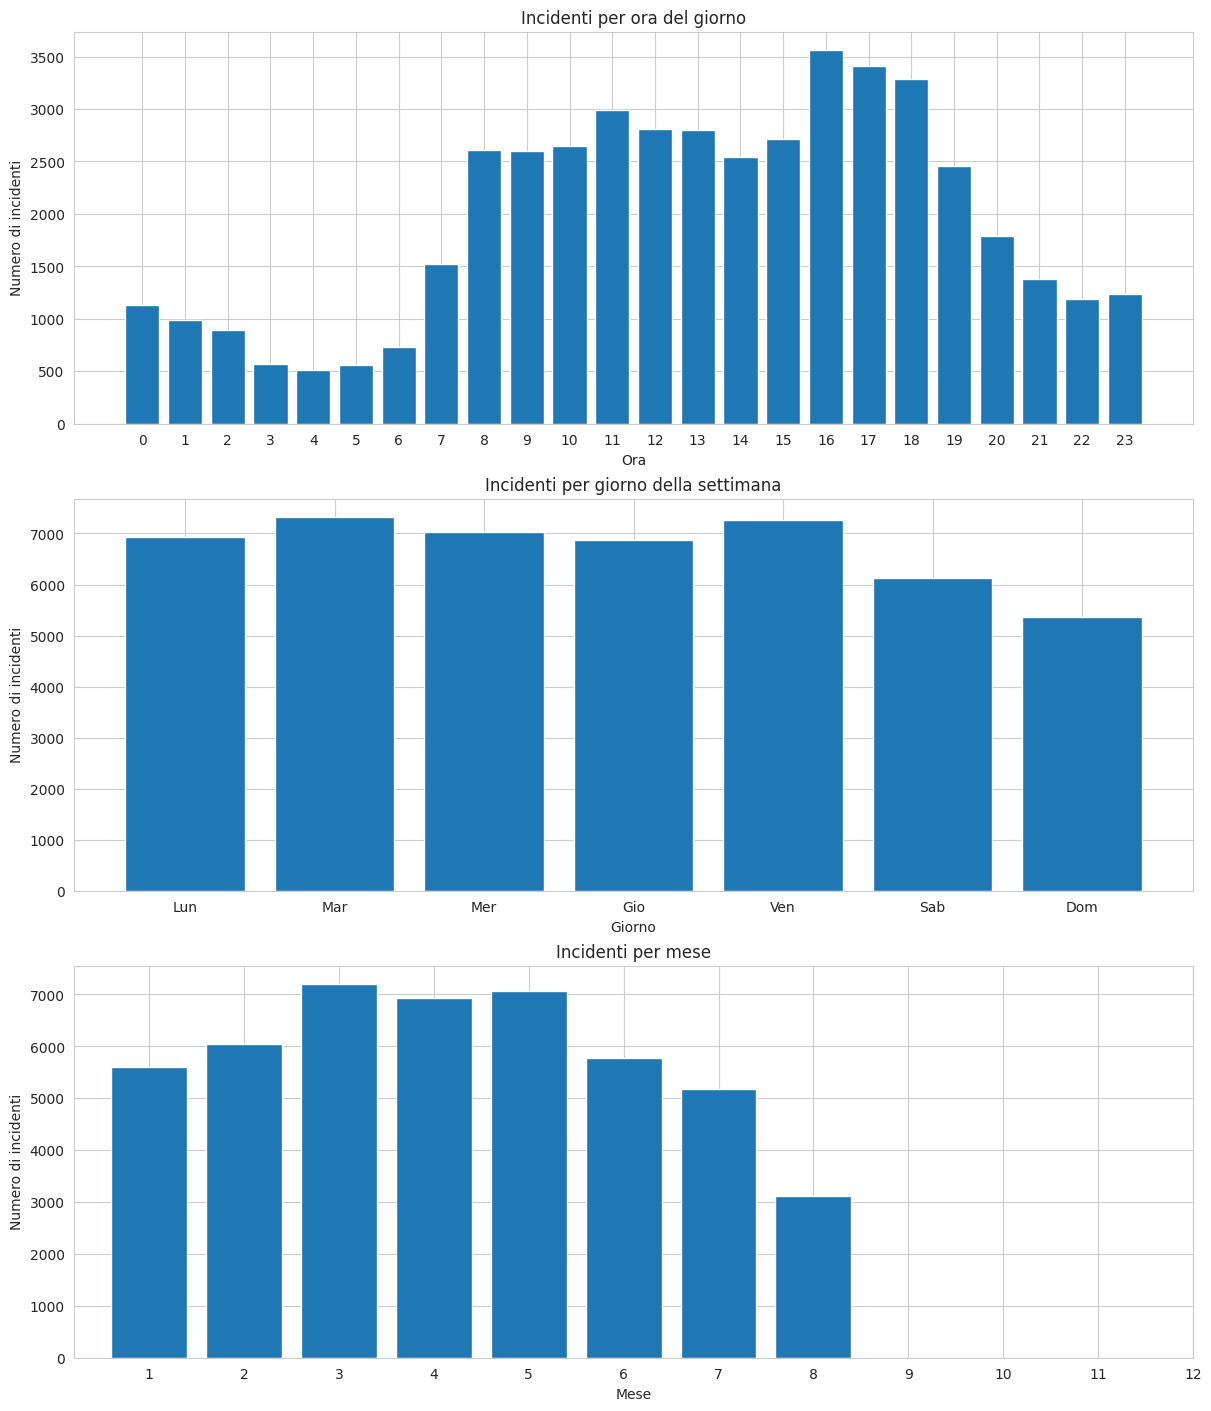

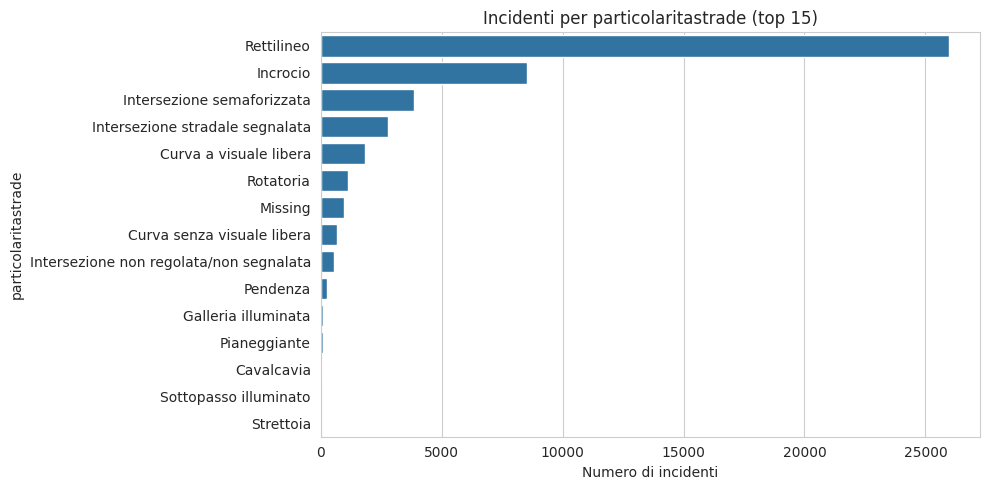

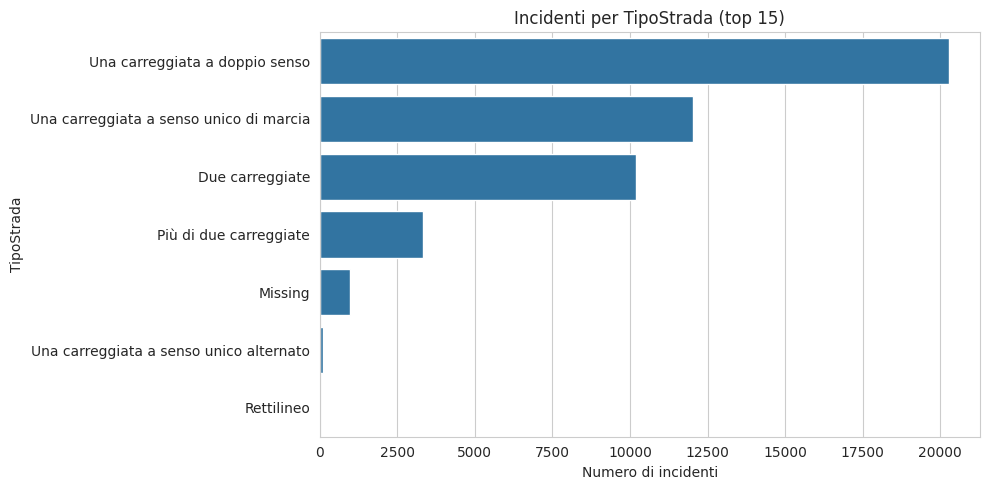

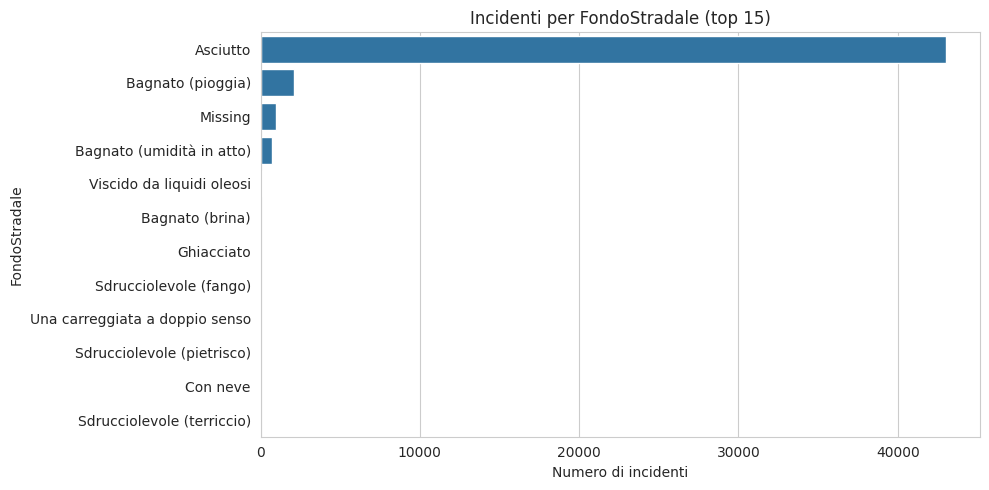

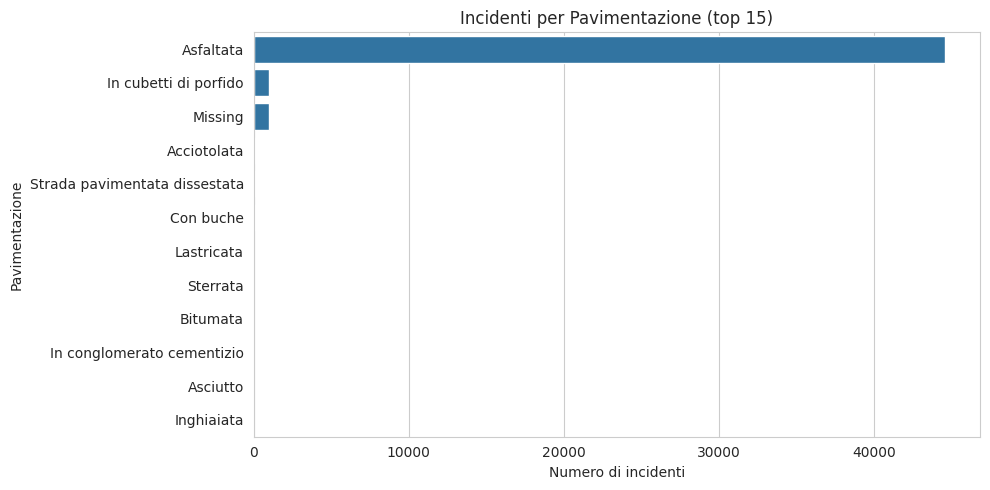

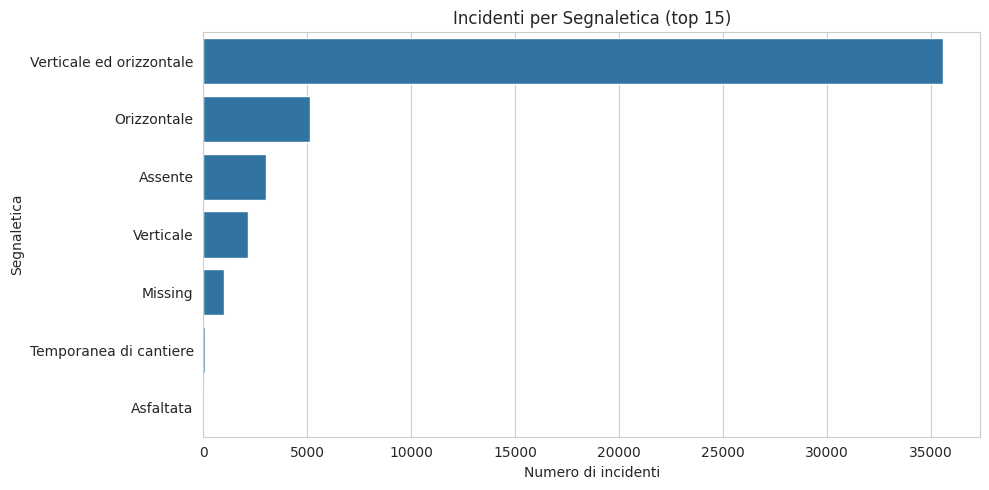

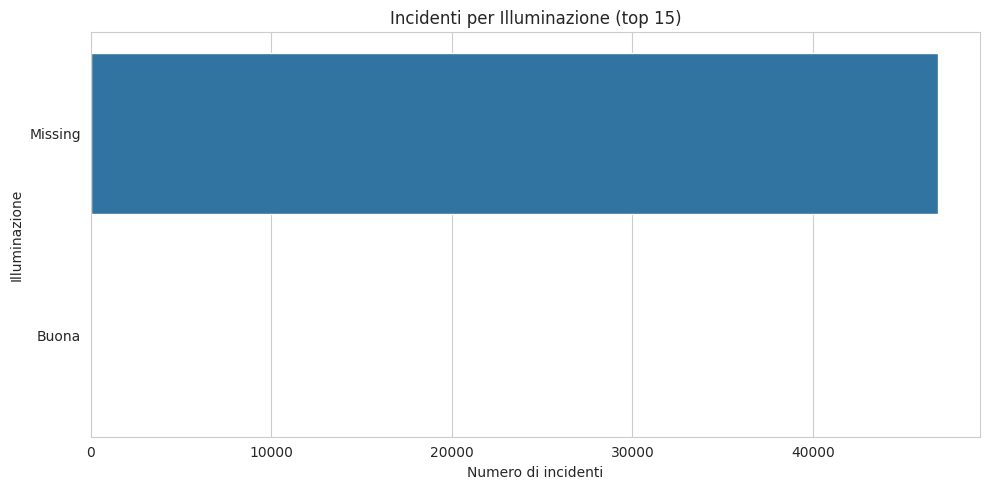

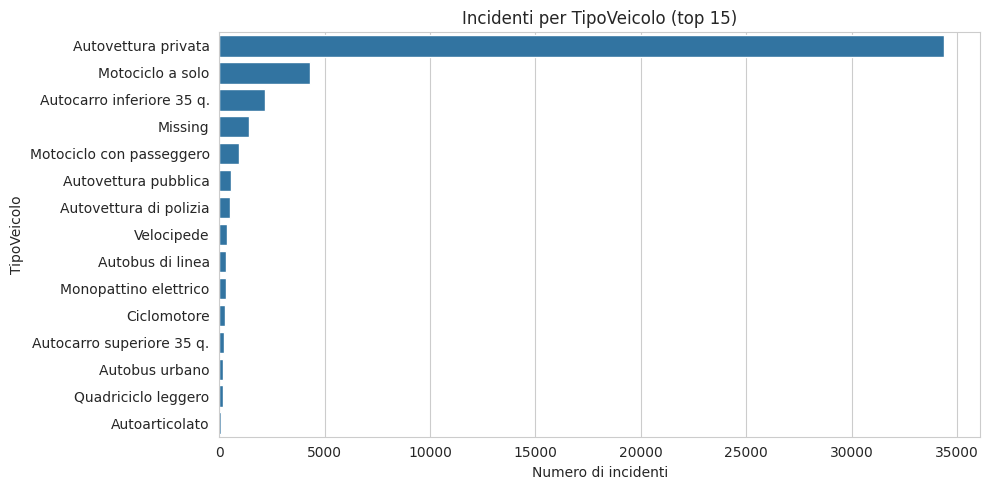

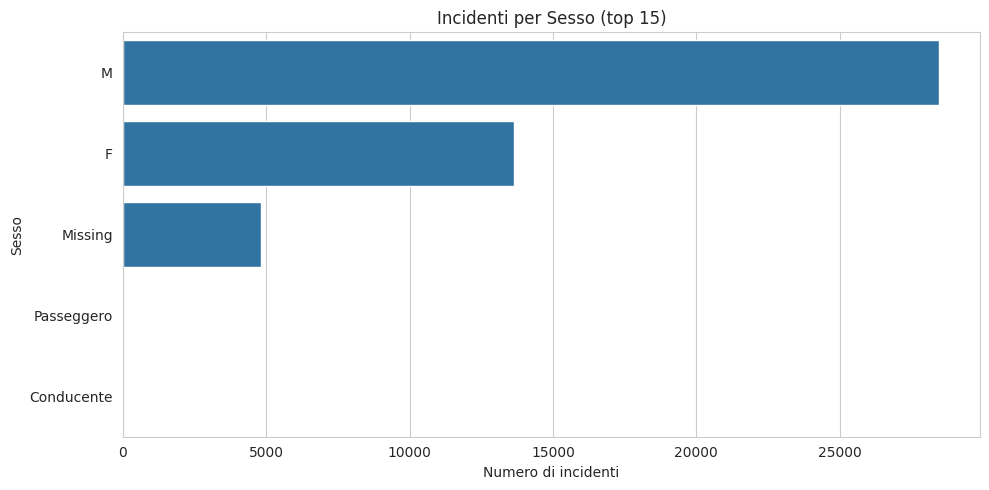

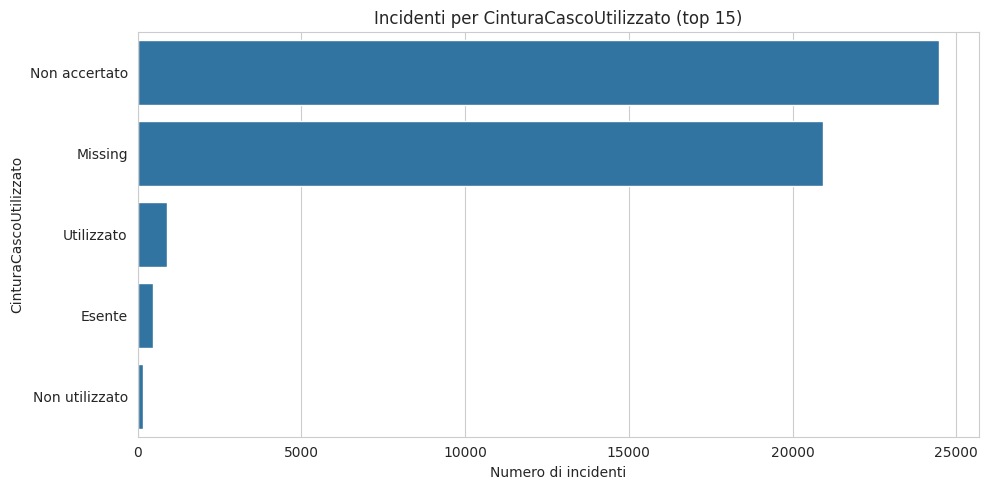

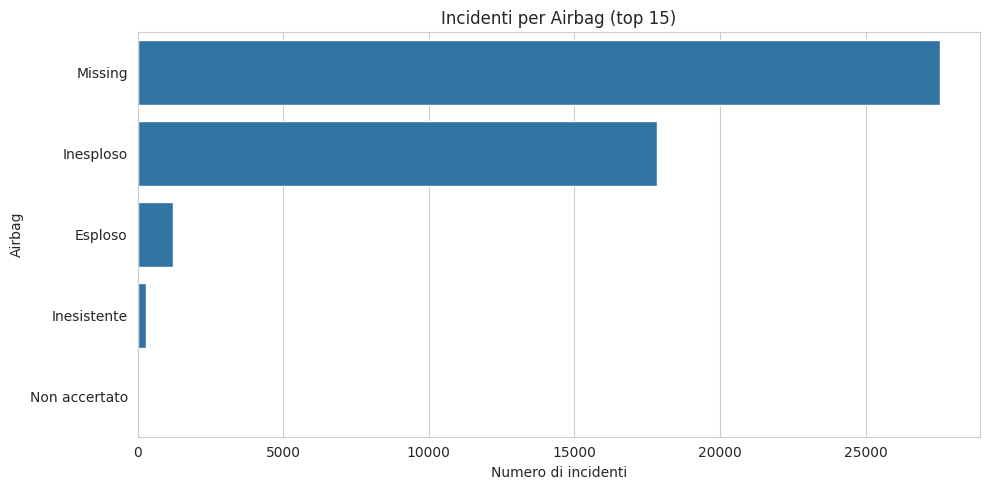

In [17]:
base_dir = "/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/data_2022"
inc_dir = "incidenti/csv"
plot_distributions(base_dir, inc_dir)